# 🛡️ Network Intrusion & Cyber Threat Detection AI
**Student / Author:** Salman Ali

Hum yahan step-by-step model train karenge!

In [1]:
# Cell 1: Yahan hum pehla code likhenge

In [3]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizations ka clean theme set karna
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)

print("✓ Libraries successfully imported!")

✓ Libraries successfully imported!


In [4]:
# File path define karna (notebooks folder se bahar nikal kar data folder me jana)
data_path = os.path.join("..", "data", "network_traffic.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "network_traffic.csv")

# CSV file ko Pandas DataFrame me load karna
df = pd.read_csv(data_path)

print(f"✓ Dataset Successfully Loaded!")
print(f"Total Network Packets (Rows): {df.shape[0]:,}")
print(f"Total Features (Columns):       {df.shape[1]}")

# Pehle 5 network packets ka data dekhna
df.head()

✓ Dataset Successfully Loaded!
Total Network Packets (Rows): 8,000
Total Features (Columns):       22


,duration,protocol_type,service,flag,src_bytes,dst_bytes,wrong_fragment,urgent,hot,num_failed_logins,...,srv_count,serror_rate,same_srv_rate,diff_srv_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,attack_type,is_attack
0,6.396030,tcp,dns,SF,94,9644,0,0,0,0,...,2,0.04,0.92,0.08,172,250,0.90,0.12,Normal,0
1,38.970000,tcp,ssh,SF,1973,691,0,0,1,3,...,4,0.00,1.00,0.00,10,29,0.78,0.07,R2L,1
2,0.000000,tcp,private,S0,60,0,0,0,0,0,...,348,0.78,0.94,0.01,217,24,0.17,0.14,DoS,1
3,0.000000,udp,other,S0,44,0,1,0,0,0,...,161,0.95,0.78,0.04,211,19,0.04,0.29,DoS,1
4,1.024861,tcp,smtp,SF,592,445,0,0,0,0,...,5,0.01,0.85,0.03,25,159,0.76,0.04,Normal,0


--- Network Traffic Breakdown ---
• Normal  : 4,227 packets (52.8%)
• DoS     : 2,359 packets (29.5%)
• Probe   : 933 packets (11.7%)
• R2L     : 332 packets (4.2%)
• U2R     : 149 packets (1.9%)


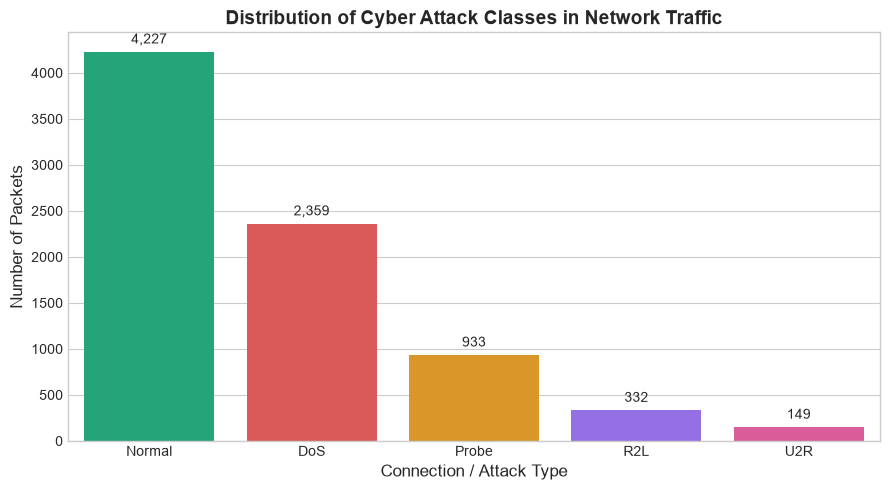

In [5]:
# 1. Pehle text form me tadaad aur percentage dekhte hain
print("--- Network Traffic Breakdown ---")
counts = df['attack_type'].value_counts()
percentages = df['attack_type'].value_counts(normalize=True) * 100

for attack, count in counts.items():
    pct = percentages[attack]
    print(f"• {attack:<8}: {count:,} packets ({pct:.1f}%)")

# 2. Ab iska khoobsoorat Bar Chart banate hain
plt.figure(figsize=(9, 5))
colors = ['#10b981', '#ef4444', '#f59e0b', '#8b5cf6', '#ec4899']

ax = sns.barplot(x=counts.index, y=counts.values, palette=colors)
plt.title('Distribution of Cyber Attack Classes in Network Traffic', fontsize=14, fontweight='bold')
plt.xlabel('Connection / Attack Type', fontsize=12)
plt.ylabel('Number of Packets', fontsize=12)

# Bars k upar exact number likhna
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Numerical aur Categorical features alag karna
categorical_features = ['protocol_type', 'service', 'flag']
numerical_features = [
    'duration', 'src_bytes', 'dst_bytes', 'wrong_fragment',
    'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'count', 'srv_count', 'serror_rate', 'same_srv_rate',
    'diff_srv_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate'
]

# X = Features (Input), y = Attack Type (Output / Target)
X = df[numerical_features + categorical_features]
y = df['attack_type']

# 2. Train-Test Split (80% training, 20% testing)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Preprocessor Pipeline (Numbers ko scale karna, Text ko 0/1 One-Hot karna)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# 4. Data transform karna
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"✓ Data Preprocessing Complete!")
print(f"Training Packets: {X_train.shape[0]:,} (80%)")
print(f"Testing Packets:  {X_test.shape[0]:,} (20%)")
print(f"Total Prepared Features (after encoding): {X_train.shape[1]}")

✓ Data Preprocessing Complete!
Training Packets: 6,400 (80%)
Testing Packets:  1,600 (20%)
Total Prepared Features (after encoding): 34


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 3 Models define karna
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=12, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
}

results = []
trained_models = {}

print("--- AI Models Ki Training Shuru ---")
for name, clf in models.items():
    print(f"Training {name}...")
    # Model ko sikhana (Training)
    clf.fit(X_train, y_train)
    trained_models[name] = clf
    
    # Model ka test lena (Prediction on unseen test data)
    y_pred = clf.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
    
    results.append({
        'Model Name': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score': round(f1, 4)
    })

# Scores ki Table banana
df_results = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
print("\n✓ Training Complete! Final Scorecard:")
df_results

--- AI Models Ki Training Shuru ---
Training Logistic Regression...
Training Decision Tree...
Training Random Forest...

✓ Training Complete! Final Scorecard:


,Model Name,Accuracy (%),Precision (%),Recall (%),F1-Score
0,Logistic Regression,100.00,100.00,100.00,1.0000
1,Random Forest,100.00,100.00,100.00,1.0000
2,Decision Tree,99.69,99.68,99.69,0.9968


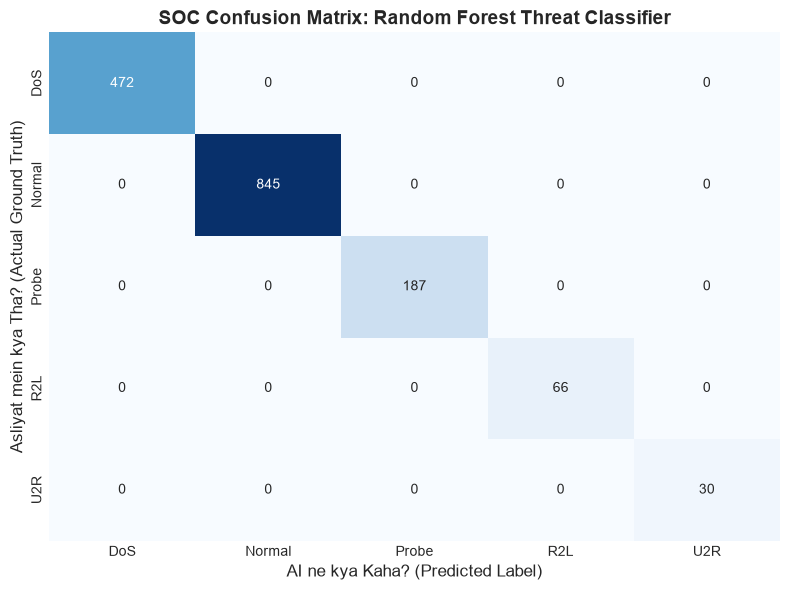

--- Har Attack Type Ka Individual Score Card ---
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00       472
      Normal       1.00      1.00      1.00       845
       Probe       1.00      1.00      1.00       187
         R2L       1.00      1.00      1.00        66
         U2R       1.00      1.00      1.00        30

    accuracy                           1.00      1600
   macro avg       1.00      1.00      1.00      1600
weighted avg       1.00      1.00      1.00      1600



In [8]:
from sklearn.metrics import confusion_matrix, classification_report

# Champion model uthana
best_model = trained_models['Random Forest']
y_pred_best = best_model.predict(X_test)

# Confusion Matrix calculate karna
classes = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred_best, labels=classes)

# Heatmap plot karna
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=classes, yticklabels=classes, cbar=False)

plt.title('SOC Confusion Matrix: Random Forest Threat Classifier', fontsize=14, fontweight='bold')
plt.xlabel('AI ne kya Kaha? (Predicted Label)', fontsize=12)
plt.ylabel('Asliyat mein kya Tha? (Actual Ground Truth)', fontsize=12)

plt.tight_layout()
plt.show()

# Class-by-class detail report
print("--- Har Attack Type Ka Individual Score Card ---")
print(classification_report(y_test, y_pred_best, zero_division=0))

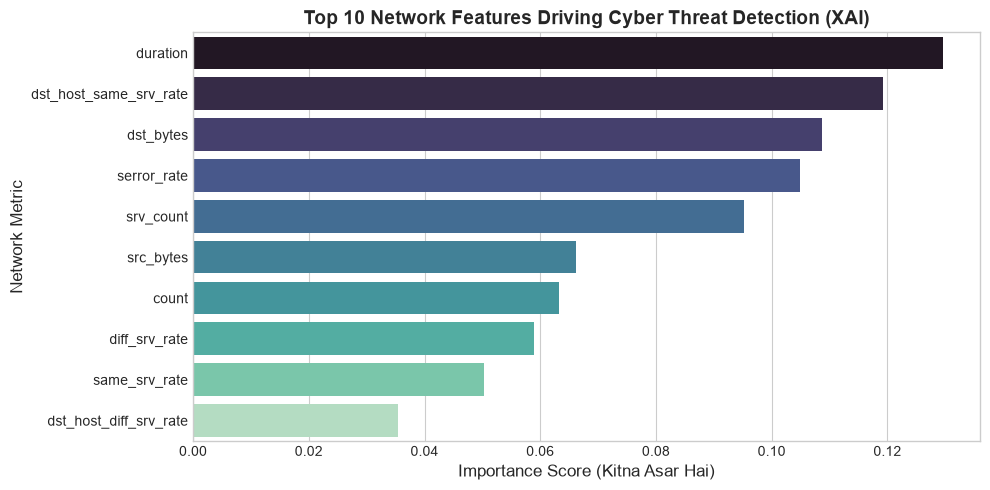

Top 3 Sab Se Ahem Features:
  duration -> Score: 0.1295
  dst_host_same_srv_rate -> Score: 0.1193
  dst_bytes -> Score: 0.1087


In [9]:
# Encoded features ke asal naam nikalna
cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = numerical_features + list(cat_names)

# Random Forest se Feature Importance nikalna
importances = best_model.feature_importances_
df_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

# Top 10 Features ka Bar Chart
plt.figure(figsize=(10, 5))
sns.barplot(data=df_importance, x='Importance', y='Feature', palette='mako')

plt.title('Top 10 Network Features Driving Cyber Threat Detection (XAI)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score (Kitna Asar Hai)', fontsize=12)
plt.ylabel('Network Metric', fontsize=12)

plt.tight_layout()
plt.show()

print("Top 3 Sab Se Ahem Features:")
for i, row in df_importance.head(3).iterrows():
    print(f"  {row['Feature']} -> Score: {row['Importance']:.4f}")

In [10]:
import joblib

# 1. Champion Model aur Preprocessor ko save karna
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/cyber_threat_detector.joblib")
joblib.dump(preprocessor, "models/preprocessor.joblib")
print("✓ Model & Preprocessor Successfully Saved!")

# 2. Live Packet Test Function (SOC Simulator)
def inspect_packet(packet_dict):
    df_pkt = pd.DataFrame([packet_dict])
    X_pkt = preprocessor.transform(df_pkt)
    pred = best_model.predict(X_pkt)[0]
    conf = np.max(best_model.predict_proba(X_pkt)[0]) * 100
    
    status = "🟢 BENIGN (Allow)" if pred == "Normal" else f"🚨 ATTACK DETECTED: {pred.upper()} (Block IP!)"
    print(f"[PACKET INSPECTION] Result: {status} | Confidence: {conf:.1f}%")

# Test: Normal Packet vs DoS Flood Packet
print("\n--- Testing Live Packets ---")
inspect_packet({
    'duration': 1.0, 'protocol_type': 'tcp', 'service': 'http', 'flag': 'SF',
    'src_bytes': 350, 'dst_bytes': 4000, 'wrong_fragment': 0, 'urgent': 0, 'hot': 0,
    'num_failed_logins': 0, 'logged_in': 1, 'count': 4, 'srv_count': 4,
    'serror_rate': 0.0, 'same_srv_rate': 1.0, 'diff_srv_rate': 0.0,
    'dst_host_count': 50, 'dst_host_srv_count': 180,
    'dst_host_same_srv_rate': 0.95, 'dst_host_diff_srv_rate': 0.02
})

inspect_packet({
    'duration': 0.0, 'protocol_type': 'tcp', 'service': 'private', 'flag': 'S0',
    'src_bytes': 44, 'dst_bytes': 0, 'wrong_fragment': 0, 'urgent': 0, 'hot': 0,
    'num_failed_logins': 0, 'logged_in': 0, 'count': 450, 'srv_count': 420,
    'serror_rate': 0.98, 'same_srv_rate': 0.95, 'diff_srv_rate': 0.0,
    'dst_host_count': 255, 'dst_host_srv_count': 4,
    'dst_host_same_srv_rate': 0.02, 'dst_host_diff_srv_rate': 0.20
})

✓ Model & Preprocessor Successfully Saved!

--- Testing Live Packets ---
[PACKET INSPECTION] Result: 🟢 BENIGN (Allow) | Confidence: 93.0%
[PACKET INSPECTION] Result: 🚨 ATTACK DETECTED: DOS (Block IP!) | Confidence: 100.0%
